<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%A2%D1%80%D0%B5%D0%BD%D1%83%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA_%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


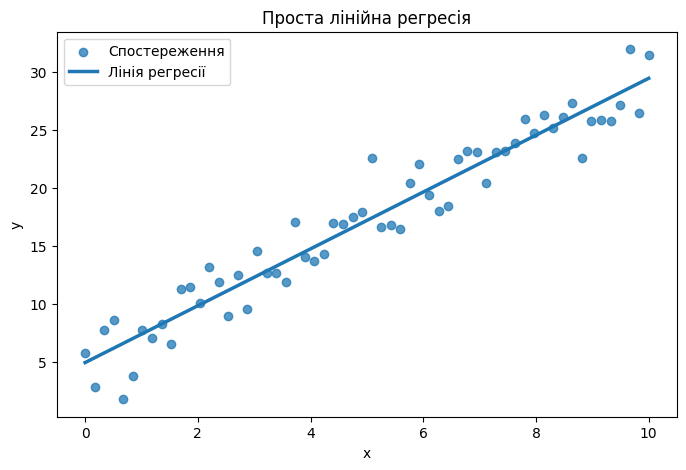

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [3]:
# TODO: Самостійне завдання 1
# 1. Створення 2D-масиву ознак для коректної роботи зі scikit-learn
X_new = np.array([[2], [5], [8]])

# 2. Отримання прогнозів навченої моделі
predictions = simple_model.predict(X_new)

# 3. Створення та виведення DataFrame
df_task1 = pd.DataFrame({
    'x': X_new.ravel(),
    'prediction': predictions
})
display(df_task1)

# 4. Пояснення змісту коефіцієнта b1
print(f"Пояснення коефіцієнта b1 ({simple_model.coef_[0]:.3f}):")
print(f"Коефіцієнт нахилу b1 показує, що при зростанні ознаки x на 1 одиницю модель прогнозує збільшення цільової змінної y в середньому приблизно на {simple_model.coef_[0]:.3f} одиниці.")

,x,prediction
0,2,9.809730
1,5,17.163214
2,8,24.516697


Пояснення коефіцієнта b1 (2.451):
Коефіцієнт нахилу b1 показує, що при зростанні ознаки x на 1 одиницю модель прогнозує збільшення цільової змінної y в середньому приблизно на 2.451 одиниці.


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [4]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [5]:
# TODO: Самостійне завдання 2
# Вхідні дані
x2 = np.array([2, 4, 6, 8, 10], dtype=float)
y2 = np.array([7.0, 11.0, 16.0, 19.0, 25.0])

# Обчислення середніх значень
x2_bar = x2.mean()
y2_bar = y2.mean()

# Ручний розрахунок коефіцієнтів за формулами МНК
b1_manual = np.sum((x2 - x2_bar) * (y2 - y2_bar)) / np.sum((x2 - x2_bar) ** 2)
b0_manual = y2_bar - b1_manual * x2_bar

# Розрахунок через scikit-learn
model_task2 = LinearRegression().fit(x2.reshape(-1, 1), y2)
b0_sklearn = model_task2.intercept_
b1_sklearn = model_task2.coef_[0]

# Порівняння результатів
print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={b0_sklearn:.4f}, b1={b1_sklearn:.4f}')
print(f'Повний збіг результатів: {np.isclose(b0_manual, b0_sklearn) and np.isclose(b1_manual, b1_sklearn)}')

Ручний розрахунок: b0=2.4000, b1=2.2000
scikit-learn:     b0=2.4000, b1=2.2000
Повний збіг результатів: True


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [6]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [7]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [8]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [10]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [11]:
# TODO: Самостійне завдання 3
# Розрахунок кожної метрики окремо за допомогою імпортованих функцій sklearn
mae_baseline = mean_absolute_error(y_test, baseline_pred)
rmse_baseline = root_mean_squared_error(y_test, baseline_pred)
r2_baseline = r2_score(y_test, baseline_pred)

mae_linear = mean_absolute_error(y_test, linear_pred)
rmse_linear = root_mean_squared_error(y_test, linear_pred)
r2_linear = r2_score(y_test, linear_pred)

# Зведення результатів у порівняльну таблицю
df_metrics_task3 = pd.DataFrame({
    'MAE': [mae_baseline, mae_linear],
    'RMSE': [rmse_baseline, rmse_linear],
    'R2': [r2_baseline, r2_linear]
}, index=['DummyRegressor', 'LinearRegression'])

display(df_metrics_task3)

,MAE,RMSE,R2
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


**Ваш висновок:**  
Модель `LinearRegression` очікувано перевершує тривіальний бейзлайн `DummyRegressor` за всіма метриками: абсолютна середня помилка MAE зменшилася з 64.01 до 42.79, середньоквадратична RMSE впала з 73.22 до 53.85, а коефіцієнт детермінації $R^2$ зріс із від'ємного значення (-0.012) до 0.453, що підтверджує наявність значущого лінійного зв'язку між ознаками та рівнем прогресування хвороби. Не варто спиратися лише на одну метрику, оскільки MAE показує середню типову похибку без урахування аномалій, RMSE сильно штрафує великі викиди через зведення залишків у квадрат, а $R^2$ демонструє відносну частку поясненої дисперсії відносно константного прогнозу середнім, тому тільки їхня сукупність дає повне розуміння точності та стабільності алгоритму.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

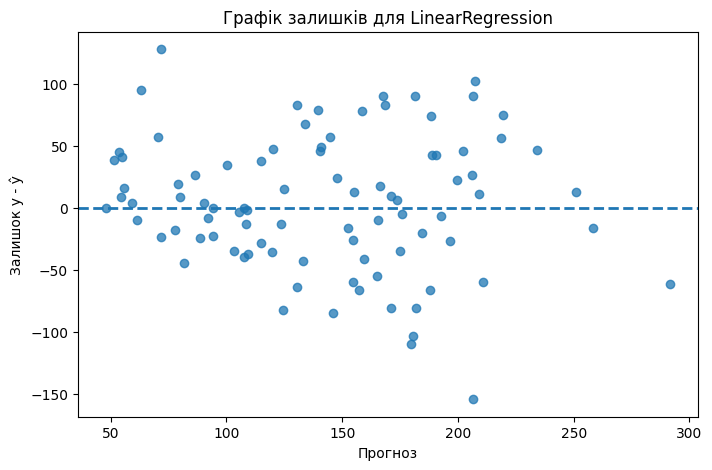

In [12]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


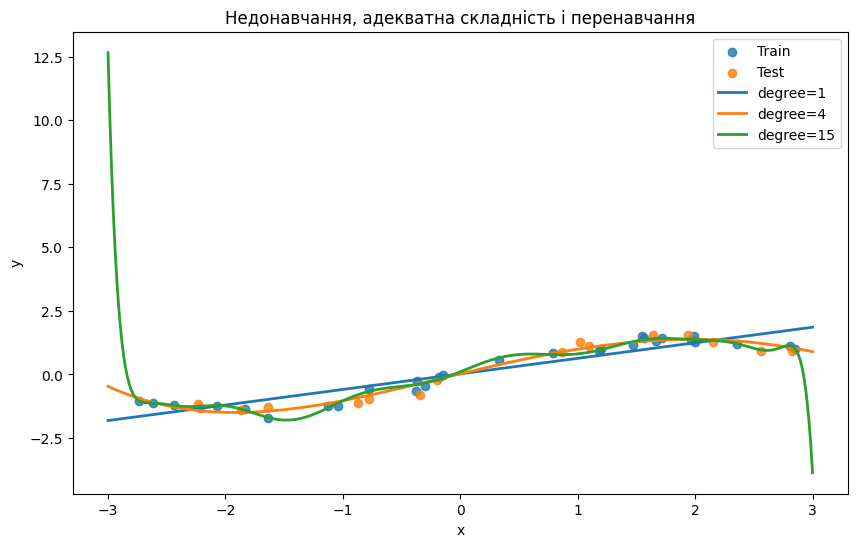

In [14]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [15]:
# TODO: Самостійне завдання 4
# Перелік ступенів для дослідження
degrees_to_test = [1, 2, 4, 6, 10, 15]
poly_results = []
poly_models = {}

for deg in degrees_to_test:
    model, metrics = fit_polynomial(deg)
    poly_models[deg] = model
    poly_results.append(metrics)

# Створення та виведення порівняльної таблиці
df_poly_task4 = pd.DataFrame(poly_results)
display(df_poly_task4)

# Визначення ступеня з мінімальним test_rmse
best_poly_row = df_poly_task4.loc[df_poly_task4['test_rmse'].idxmin()]
best_deg = int(best_poly_row['degree'])
print(f"Ступінь із мінімальним test_rmse: degree = {best_deg}")
print(f"Помилка на train: {best_poly_row['train_rmse']:.4f} | Помилка на test: {best_poly_row['test_rmse']:.4f}")

# Пояснення
print("\nПояснення щодо train-помилки:")
print("Мінімальна помилка на train не гарантує оптимальності моделі, оскільки зі зростанням степеня полінома (наприклад, 10 або 15) алгоритм отримує надмірну кількість параметрів і починає підлаштовуватися під випадковий шум та поодинокі викиди у навчальній вибірці (перенавчання, overfitting). Як результат, помилка train_rmse наближається до нуля, проте лінія регресії починає здійснювати різкі нефізичні коливання, що призводить до зростання помилки на нових спостереженнях (test_rmse) і втрати генералізації.")

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,2,0.392821,0.463992
2,4,0.144969,0.203183
3,6,0.137065,0.196267
4,10,0.129074,0.191782
5,15,0.091024,0.244266


Ступінь із мінімальним test_rmse: degree = 10
Помилка на train: 0.1291 | Помилка на test: 0.1918

Пояснення щодо train-помилки:
Мінімальна помилка на train не гарантує оптимальності моделі, оскільки зі зростанням степеня полінома (наприклад, 10 або 15) алгоритм отримує надмірну кількість параметрів і починає підлаштовуватися під випадковий шум та поодинокі викиди у навчальній вибірці (перенавчання, overfitting). Як результат, помилка train_rmse наближається до нуля, проте лінія регресії починає здійснювати різкі нефізичні коливання, що призводить до зростання помилки на нових спостереженнях (test_rmse) і втрати генералізації.


## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [16]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [17]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [18]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [19]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [20]:
# TODO: Самостійне завдання 5
# Ініціалізація моделей у вигляді пайплайнів із попереднім масштабуванням
pipelines = {
    'LinearRegression': Pipeline([
        ('scale', StandardScaler()),
        ('reg', LinearRegression())
    ]),
    'Ridge (alpha=1.0)': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Ridge(alpha=1.0, random_state=RANDOM_STATE))
    ]),
    'Lasso (alpha=1.0)': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Lasso(alpha=1.0, max_iter=20000, random_state=RANDOM_STATE))
    ]),
    'ElasticNet (alpha=0.1, l1=0.5)': Pipeline([
        ('scale', StandardScaler()),
        ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000, random_state=RANDOM_STATE))
    ])
}

comparison_data = []

# Навчання та збір метрик
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    comparison_data.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred)
    })

df_task5 = pd.DataFrame(comparison_data).set_index('Model')
display(df_task5)

,MAE,RMSE,R2
Model,,,
LinearRegression,42.794095,53.853446,0.452603
Ridge (alpha=1.0),42.811999,53.777454,0.454147
Lasso (alpha=1.0),42.802984,53.146666,0.466877
"ElasticNet (alpha=0.1, l1=0.5)",42.873332,53.539343,0.458970


## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [22]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [23]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [24]:
# TODO: Самостійне завдання 6
# 1. Пайплайн для Lasso
lasso_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=30000, random_state=RANDOM_STATE))
])

# 2. Сітка з 15 значень alpha у логарифмічному масштабі
param_grid_lasso = {
    'reg__alpha': np.logspace(-3, 2, 15)
}

# 3. Налаштування та запуск GridSearchCV
lasso_grid = GridSearchCV(
    lasso_pipeline,
    param_grid=param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
lasso_grid.fit(X_train, y_train)

# Збір метрик найкращої моделі Lasso
best_lasso_alpha = lasso_grid.best_params_['reg__alpha']
lasso_cv_rmse = -lasso_grid.best_score_
lasso_test_rmse = root_mean_squared_error(y_test, lasso_grid.predict(X_test))

# Збір метрик раніше налаштованого Ridge
best_ridge_alpha = ridge_search.best_params_['reg__alpha']
ridge_cv_rmse = -ridge_search.best_score_
ridge_test_rmse = root_mean_squared_error(y_test, ridge_search.predict(X_test))

# 4. Формування підсумкової порівняльної таблиці
df_grid_comparison = pd.DataFrame({
    'Best Alpha': [best_ridge_alpha, best_lasso_alpha],
    'CV RMSE': [ridge_cv_rmse, lasso_cv_rmse],
    'Test RMSE': [ridge_test_rmse, lasso_test_rmse]
}, index=['Ridge', 'Lasso'])

display(df_grid_comparison)

# Підрахунок відсіяних ознак моделлю Lasso
best_lasso_estimator = lasso_grid.best_estimator_.named_steps['reg']
zero_weights = np.sum(np.isclose(best_lasso_estimator.coef_, 0))
print(f"\nКількість занулених ознак у найкращому Lasso: {zero_weights} із {X.shape[1]}")

,Best Alpha,CV RMSE,Test RMSE
Ridge,1.00000,55.374175,53.777454
Lasso,0.13895,55.349419,53.688412



Кількість занулених ознак у найкращому Lasso: 1 із 10


## 16. Як регуляризація змінює коефіцієнти

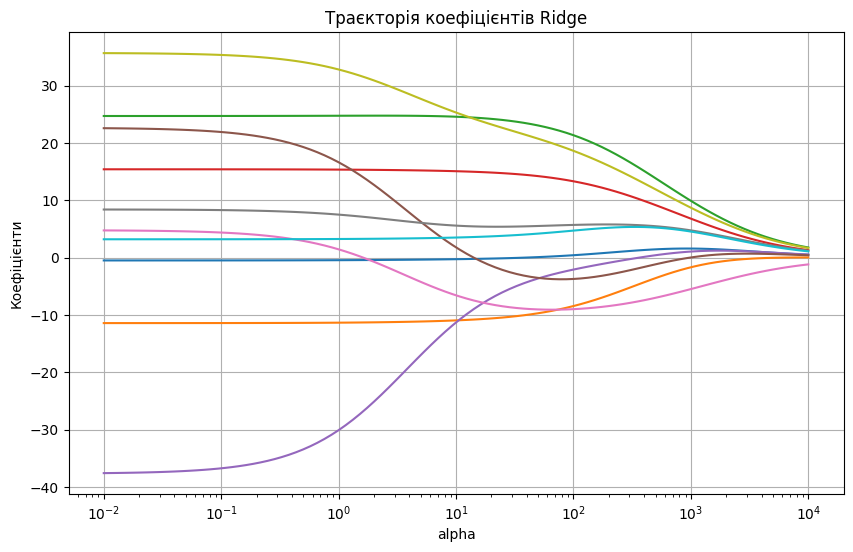

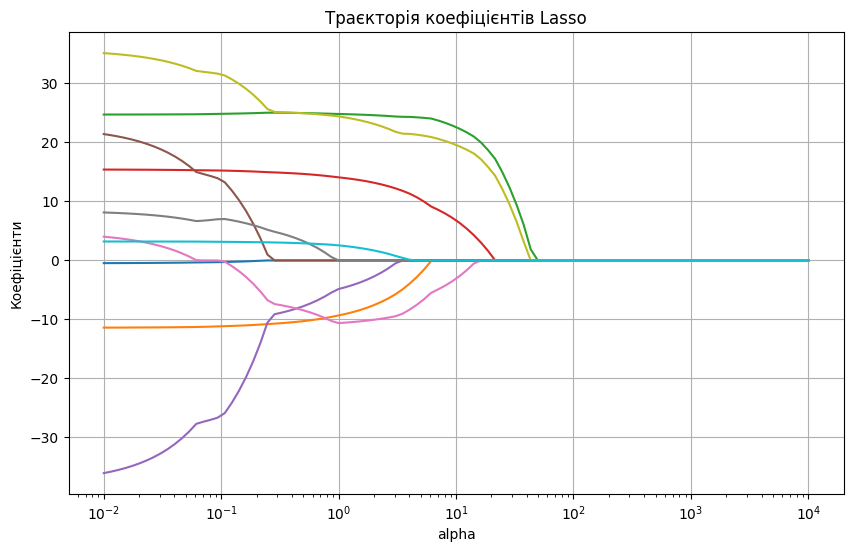

In [25]:
alphas = np.logspace(-2, 4, 100)

coefs_ridge = []
coefs_lasso = []

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for a in alphas:
    ridge_m = Ridge(alpha=a).fit(X_scaled, y)
    coefs_ridge.append(ridge_m.coef_)
    lasso_m = Lasso(alpha=a, max_iter=20000).fit(X_scaled, y)
    coefs_lasso.append(lasso_m.coef_)

plt.figure(figsize=(10, 6))
plt.plot(alphas, coefs_ridge)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнти')
plt.title('Траєкторія коефіцієнтів Ridge')
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(alphas, coefs_lasso)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнти')
plt.title('Траєкторія коефіцієнтів Lasso')
plt.grid(True)
plt.show()